<a href="https://colab.research.google.com/github/JariusF10-8/bt4222/blob/main/notebooks/eda/Dataset_Overview.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MIND-small: dataset and embedding overview

Descriptive EDA on the raw source files; this notebook does not prepare modelling outputs. Run `../02_Data_Preprocessing.ipynb` for the shared handoff. Supports local execution and Colab with a cloned repository. All source files remain unchanged.

## 1. Imports
Pandas loads the files into DataFrames (tables). Path builds file locations. The csv setting used below preserves literal quotation marks in titles and entity JSON.


In [1]:
from pathlib import Path
import csv
import sys

import pandas as pd
from IPython.display import display

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)


Python version: 3.13.16
Pandas version: 3.0.5


## 2. Configure repository and raw data paths

Locally the repository is detected from the working directory. In Colab mount Drive and configure environment variables as described in README.md.

In [2]:
from pathlib import Path
import os
import sys

# In Colab, clone/open the repository first; set BT4222_PROJECT_ROOT if needed.
# For shared Drive data, set MIND_RAW_DIR to the folder containing MINDsmall_train.
try:
    from google.colab import drive
except ImportError:
    pass
else:
    drive.mount("/content/drive")

configured_root = os.environ.get("BT4222_PROJECT_ROOT")
if configured_root:
    PROJECT_ROOT = Path(configured_root).expanduser().resolve()
else:
    PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                         if (p / "src/data_loading.py").is_file()), None)
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src/data_loading.py").is_file():
    raise FileNotFoundError("Open the cloned repo, or set BT4222_PROJECT_ROOT to its path.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
DATA_ROOT = Path(os.environ.get("MIND_RAW_DIR", str(PROJECT_ROOT / "data/raw"))).expanduser()


## 3. Set the data location and check the files
Google Drive's **My Drive** appears as **MyDrive** in the mounted path. Spaces and capitalisation in the remaining folder names must match.

This cell stops with a clear message if the folder or a required file is missing. It does not create an empty folder that could hide a path mistake.


In [3]:
SPLIT = "MINDsmall_train"

DATA_DIR = DATA_ROOT / SPLIT
BEHAVIORS_FILE = DATA_DIR / "behaviors.tsv"
NEWS_FILE = DATA_DIR / "news.tsv"

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Folder not found: {DATA_DIR}\n"
        "Check that Drive is mounted with the correct Google account, "
        "then check folder names and any extra folder created when extracting the ZIP."
    )

for file_path in [BEHAVIORS_FILE, NEWS_FILE]:
    if not file_path.is_file():
        raise FileNotFoundError(
            f"Required file not found: {file_path}\n"
            "The extracted TSV files should be directly inside the selected split folder."
        )
    print(f"Found: {file_path.name} ({file_path.stat().st_size / 1024**2:.1f} MiB)")

print("Selected split:", SPLIT)
print("Data folder:", DATA_DIR)


Found: behaviors.tsv (87.8 MiB)
Found: news.tsv (39.3 MiB)
Selected split: MINDsmall_train
Data folder: /opt/bt4222/bt4222-main/data/raw/MINDsmall_train


## 4. Load the two TSV files
- `sep="\t"`: fields are separated by tabs.
- `header=None`: the files do not contain a header row.
- `names=...`: provide the column names.
- `dtype="string"`: keep identifiers and other raw fields as strings.
- `keep_default_na=False, na_values=[""]`: treat empty fields as missing while preserving literal text such as "NA".
- `quoting=csv.QUOTE_NONE`: read quotation marks literally in these tab-separated records.

Histories, impressions and entity JSON remain in their original string form for now. No rows are dropped and IDs are not remapped.


In [4]:
from src.preprocessing import BEHAVIORS_COLUMNS, NEWS_COLUMNS, read_sampling_tsv

behaviors = read_sampling_tsv(BEHAVIORS_FILE, BEHAVIORS_COLUMNS)
news = read_sampling_tsv(NEWS_FILE, NEWS_COLUMNS)
print("behaviors shape:", behaviors.shape)
print("news shape:", news.shape)


behaviors shape: (156965, 5)
news shape: (51282, 8)


## 5. Preview rows and column types
One behaviors row represents one impression event, which can contain multiple candidate articles. One news row describes an article. The preview is just a small sample, not a full analysis.


In [5]:
print("First 5 behavior records:")
display(behaviors.head())

print("First 5 article records:")
display(news.head())

print("Behavior column types:")
display(behaviors.dtypes.rename("data_type").to_frame())

print("News column types:")
display(news.dtypes.rename("data_type").to_frame())


First 5 behavior records:


,impression_id,user_id,time,history,impressions
0,1,U13740,11/11/2019 9:05:58 AM,N55189 N42782 N34694 N45794 N18445 N63302 N104...,N55689-1 N35729-0
1,2,U91836,11/12/2019 6:11:30 PM,N31739 N6072 N63045 N23979 N35656 N43353 N8129...,N20678-0 N39317-0 N58114-0 N20495-0 N42977-0 N...
2,3,U73700,11/14/2019 7:01:48 AM,N10732 N25792 N7563 N21087 N41087 N5445 N60384...,N50014-0 N23877-0 N35389-0 N49712-0 N16844-0 N...
3,4,U34670,11/11/2019 5:28:05 AM,N45729 N2203 N871 N53880 N41375 N43142 N33013 ...,N35729-0 N33632-0 N49685-1 N27581-0
4,5,U8125,11/12/2019 4:11:21 PM,N10078 N56514 N14904 N33740,N39985-0 N36050-0 N16096-0 N8400-1 N22407-0 N6...


First 5 article records:


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, an...","Shop the notebooks, jackets, and more that the...",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"",...",[]
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding yo...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""Wik..."
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches...,Lt. Ivan Molchanets peeked over a parapet of s...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId..."
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My M...,"I felt like I was a fraud, and being an NBA wi...",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ..."
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a De...","They seem harmless, but there's a very good re...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataI..."


Behavior column types:


,data_type
impression_id,string
user_id,string
time,string
history,string
impressions,string


News column types:


,data_type
news_id,string
category,string
subcategory,string
title,string
abstract,string
url,string
title_entities,string
abstract_entities,string


## 6. Inspect basic counts
Counts apply only to the selected split. Distinct articles in news.tsv are metadata coverage, not the number of candidate exposures.

Blank or whitespace-only histories are counted as unavailable supplied histories. The number of affected impression rows differs from the number of distinct affected users. A user may have missing history in one record and a nonempty history in another.

Duplicate-row counts compare all original columns. Duplicate IDs are reported separately; review any such findings before deleting records.


In [6]:
missing_history = behaviors["history"].fillna("").str.strip().eq("")

basic_counts = pd.Series({
    "Distinct users in behavior records": behaviors["user_id"].nunique(),
    "Impression rows": len(behaviors),
    "Distinct impression IDs": behaviors["impression_id"].nunique(),
    "Article metadata rows": len(news),
    "Distinct article IDs in metadata": news["news_id"].nunique(),
    "Impression rows with unavailable history": int(missing_history.sum()),
    "Distinct users with at least one unavailable history": (
        behaviors.loc[missing_history, "user_id"].nunique()
    ),
    "Fully duplicated behavior rows": int(behaviors.duplicated().sum()),
    "Fully duplicated news rows": int(news.duplicated().sum()),
    "Repeated nonmissing impression IDs (beyond first)": int(
        behaviors["impression_id"].dropna().duplicated().sum()
    ),
    "Repeated nonmissing article IDs (beyond first)": int(
        news["news_id"].dropna().duplicated().sum()
    ),
}, name="count").to_frame()

display(basic_counts)


,count
Distinct users in behavior records,50000
Impression rows,156965
Distinct impression IDs,156965
Article metadata rows,51282
Distinct article IDs in metadata,51282
Impression rows with unavailable history,3238
Distinct users with at least one unavailable history,892
Fully duplicated behavior rows,0
Fully duplicated news rows,0
Repeated nonmissing impression IDs (beyond first),0


## 7. Inspect missingness
Report missing/blank counts, percentages and distinct nonmissing values for each raw field. A literal `[]` in an entity column is an empty annotation list, not a missing string; it is not counted as missing here.


In [7]:
def field_overview(df):
    # Identify missing, empty, and whitespace-only strings without changing df.
    blank = df.apply(lambda column: column.fillna("").str.strip().eq(""))
    nonblank = df.mask(blank)

    result = pd.DataFrame({
        "missing_or_blank_count": blank.sum(),
        "distinct_nonmissing_values": nonblank.nunique(),
    })
    if len(df):
        result["missing_or_blank_pct"] = (blank.mean() * 100).round(2)
    else:
        result["missing_or_blank_pct"] = float("nan")

    return result[[
        "missing_or_blank_count",
        "missing_or_blank_pct",
        "distinct_nonmissing_values",
    ]]

print("Behavior field overview:")
display(field_overview(behaviors))

print("News field overview:")
display(field_overview(news))


Behavior field overview:


,missing_or_blank_count,missing_or_blank_pct,distinct_nonmissing_values
impression_id,0,0.0,156965
user_id,0,0.0,50000
time,0,0.0,125501
history,3238,2.06,48868
impressions,0,0.0,143617


News field overview:


,missing_or_blank_count,missing_or_blank_pct,distinct_nonmissing_values
news_id,0,0.0,51282
category,0,0.0,17
subcategory,0,0.0,264
title,0,0.0,50434
abstract,2666,5.2,47309
url,0,0.0,51282
title_entities,0,0.0,34475
abstract_entities,0,0.0,36279


## 8. Check the timestamp range
The documented format is month/day/year followed by a 12-hour time and AM/PM. Parse into a separate Series so the original time column is retained. Unparseable nonblank strings are reported instead of silently disappearing.

These are recorded dataset times. No local timezone is assumed.


In [8]:
impression_times = pd.to_datetime(
    behaviors["time"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="coerce",
)

time_present = behaviors["time"].fillna("").str.strip().ne("")
invalid_time = time_present & impression_times.isna()

print("Earliest parsed impression time:", impression_times.min())
print("Latest parsed impression time:", impression_times.max())
print("Missing/blank timestamps:", int((~time_present).sum()))
print("Nonblank timestamps that could not be parsed:", int(invalid_time.sum()))

if invalid_time.any():
    display(behaviors.loc[invalid_time, ["impression_id", "time"]].head())


Earliest parsed impression time: 2019-11-09 00:00:19
Latest parsed impression time: 2019-11-14 23:59:13
Missing/blank timestamps: 0
Nonblank timestamps that could not be parsed: 0


## 9. Load entity and relation embeddings
Run Sections 1–8 first. These cells reuse `DATA_DIR` and `news`.

Each row is an **entity/relation ID followed by 100 numeric coordinates**. These pretrained TransE vectors are not one-hot encodings. Individual coordinates have no named meanings such as "sports" or "politics".

The loader handles tabs, spaces, and trailing whitespace. It expects MIND's headerless format and stops if a row has an unexpected number of fields. NaN or nonnumeric tokens become NaN and are counted below. No records are silently dropped.


In [9]:
import json
import numpy as np
import matplotlib.pyplot as plt

EMBEDDING_DIM = 100
embedding_columns = [f"dim_{i:03d}" for i in range(1, EMBEDDING_DIM + 1)]

def load_mind_embeddings(file_path, id_column):
    file_path = Path(file_path)
    if not file_path.is_file():
        raise FileNotFoundError(f"Embedding file not found: {file_path}")
    ids, rows = [], []
    blank_lines = 0
    with file_path.open("r", encoding="utf-8-sig") as file:
        for line_number, line in enumerate(file, start=1):
            parts = line.split()
            if not parts:
                blank_lines += 1
                continue
            if len(parts) != EMBEDDING_DIM + 1:
                raise ValueError(
                    f"{file_path.name}, line {line_number}: expected an ID and "
                    f"{EMBEDDING_DIM} values; found {len(parts)} fields."
                )
            ids.append(parts[0])
            rows.append(parts[1:])
    if not rows:
        raise ValueError(f"No embedding rows found in {file_path}")
    numeric = pd.DataFrame(rows, columns=embedding_columns).apply(
        pd.to_numeric, errors="coerce"
    ).astype("float64")
    numeric.insert(0, id_column, pd.Series(ids, dtype="string"))
    numeric.attrs["blank_lines"] = blank_lines
    numeric.attrs["file_size_mib"] = file_path.stat().st_size / 1024**2
    return numeric

entity_embeddings = load_mind_embeddings(
    DATA_DIR / "entity_embedding.vec", "entity_id"
)
relation_embeddings = load_mind_embeddings(
    DATA_DIR / "relation_embedding.vec", "relation_id"
)

print("Entity embeddings (rows, columns):", entity_embeddings.shape)
print("Relation embeddings (rows, columns):", relation_embeddings.shape)
print("Each table has 1 ID column and 100 numeric columns.")
display(entity_embeddings[["entity_id"] + embedding_columns[:5]].head())
display(relation_embeddings[["relation_id"] + embedding_columns[:5]].head())


Entity embeddings (rows, columns): (26904, 101)
Relation embeddings (rows, columns): (1091, 101)
Each table has 1 ID column and 100 numeric columns.


,entity_id,dim_001,dim_002,dim_003,dim_004,dim_005
0,Q41,-0.063388,-0.181451,0.057501,-0.091254,-0.076217
1,Q1860,0.060958,0.069934,0.015832,0.079471,-0.023362
2,Q39631,-0.093106,-0.052002,0.020556,-0.020801,0.043180
3,Q30,-0.115737,-0.179113,0.102739,-0.112469,-0.101853
4,Q60,-0.051036,-0.165637,0.132802,-0.089949,-0.146637


,relation_id,dim_001,dim_002,dim_003,dim_004,dim_005
0,P31,-0.073467,-0.132227,0.034173,-0.032769,0.008289
1,P21,-0.078436,0.108589,-0.049429,-0.131355,0.049300
2,P106,-0.052137,0.052444,-0.019886,-0.152309,0.014144
3,P735,-0.051398,0.056219,0.068029,-0.137717,-0.030050
4,P108,0.091231,0.022526,0.059349,-0.141853,0.035025


## 10. File size, missingness, duplicates and zero vectors
An embedding row represents an entity or a relationship type, not an article or impression.

- **Missing/nonnumeric cells:** values converted to NaN.
- **Infinite cells:** +inf or -inf, reported separately.
- **Repeated IDs:** additional occurrences beyond the first.
- **Duplicate complete rows:** a repeated ID with the same numeric coordinates.
- **Zero vectors:** all coordinates are zero. These cannot be used directly for cosine similarity.

The code reports these issues without imputing, normalising, or deleting rows.


In [10]:
def embedding_quality(df, id_column):
    values = df[embedding_columns].to_numpy()
    finite_rows = np.isfinite(values).all(axis=1)
    return pd.Series({
        "file_size_mib": df.attrs["file_size_mib"],
        "rows": len(df),
        "distinct_ids": df[id_column].nunique(),
        "embedding_dimensions": len(embedding_columns),
        "blank_lines": df.attrs["blank_lines"],
        "missing_or_nonnumeric_cells": int(np.isnan(values).sum()),
        "infinite_cells": int(np.isinf(values).sum()),
        "rows_with_any_nonfinite_value": int((~finite_rows).sum()),
        "repeated_id_rows_beyond_first": int(df[id_column].duplicated().sum()),
        "duplicate_complete_rows_beyond_first": int(df.duplicated().sum()),
        "zero_vector_rows": int(
            (finite_rows & np.all(values == 0, axis=1)).sum()
        ),
    })

embedding_overview = pd.DataFrame({
    "entity": embedding_quality(entity_embeddings, "entity_id"),
    "relation": embedding_quality(relation_embeddings, "relation_id"),
}).T
display(embedding_overview.round(3))

for label, df, id_column in [
    ("Entity", entity_embeddings, "entity_id"),
    ("Relation", relation_embeddings, "relation_id"),
]:
    nonfinite = ~np.isfinite(df[embedding_columns].to_numpy()).all(axis=1)
    repeated = df[id_column].duplicated(keep=False)
    if nonfinite.any() or repeated.any():
        print(f"{label}: example IDs requiring review")
        display(df.loc[nonfinite | repeated, [id_column]].head(10))


,file_size_mib,rows,distinct_ids,embedding_dimensions,blank_lines,missing_or_nonnumeric_cells,infinite_cells,rows_with_any_nonfinite_value,repeated_id_rows_beyond_first,duplicate_complete_rows_beyond_first,zero_vector_rows
entity,24.615,26904.0,26904.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
relation,0.996,1091.0,1091.0,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 11. Descriptive statistics
The first table pools all finite coordinates within a file and describes their numeric scale. It does not describe popularity or model performance.

The next tables summarise each dimension separately. Only the first 10 rows are displayed, but the full 100-row tables remain available as `entity_dimension_stats` and `relation_dimension_stats`.

NaN and infinity are excluded from statistics, with their counts reported separately. Standard deviation is the sample standard deviation (ddof=1), undefined for fewer than two observations.


In [11]:
def coordinate_statistics(df):
    values = df[embedding_columns].to_numpy()
    return pd.Series(values[np.isfinite(values)]).describe().rename(
        {"count": "finite_coordinate_count", "50%": "median"}
    )

coordinate_summary = pd.DataFrame({
    "entity": coordinate_statistics(entity_embeddings),
    "relation": coordinate_statistics(relation_embeddings),
}).T
display(coordinate_summary)

def dimension_statistics(df):
    numeric = df[embedding_columns]
    finite_only = numeric.where(np.isfinite(numeric))
    result = finite_only.describe().T.rename(
        columns={"count": "finite_count", "50%": "median"}
    )
    result["missing_or_nonnumeric_count"] = numeric.isna().sum()
    result["infinite_count"] = np.isinf(numeric).sum()
    return result

entity_dimension_stats = dimension_statistics(entity_embeddings)
relation_dimension_stats = dimension_statistics(relation_embeddings)
print("Entity dimension statistics (first 10):")
display(entity_dimension_stats.head(10))
print("Relation dimension statistics (first 10):")
display(relation_dimension_stats.head(10))


,finite_coordinate_count,mean,std,min,25%,median,75%,max
entity,2690400.0,-0.000202,0.046934,-0.335510,-0.028956,0.000265,0.029043,0.306657
relation,109100.0,-0.001562,0.071331,-0.439051,-0.034117,-0.000682,0.031127,0.368847


Entity dimension statistics (first 10):


,finite_count,mean,std,min,25%,median,75%,max,missing_or_nonnumeric_count,infinite_count
dim_001,26904.0,-0.001529,0.041140,-0.182503,-0.026999,0.003057,0.026059,0.191466,0,0
dim_002,26904.0,-0.005105,0.045242,-0.247751,-0.029846,0.000789,0.023765,0.200488,0,0
dim_003,26904.0,0.015589,0.043574,-0.144118,-0.015146,0.012697,0.044566,0.166262,0,0
dim_004,26904.0,-0.004341,0.042626,-0.230141,-0.031279,-0.002576,0.023519,0.163589,0,0
dim_005,26904.0,-0.024600,0.046097,-0.183245,-0.053795,-0.021385,0.006542,0.178345,0,0
dim_006,26904.0,-0.010650,0.044147,-0.294478,-0.029622,-0.005522,0.015240,0.216501,0,0
dim_007,26904.0,0.007585,0.043356,-0.212647,-0.020346,0.006343,0.035045,0.181270,0,0
dim_008,26904.0,0.009173,0.042649,-0.277918,-0.013959,0.011734,0.036775,0.188993,0,0
dim_009,26904.0,-0.008250,0.042334,-0.230547,-0.037129,-0.013527,0.015022,0.211377,0,0
dim_010,26904.0,0.014524,0.044483,-0.155622,-0.012119,0.013549,0.039948,0.234070,0,0


Relation dimension statistics (first 10):


,finite_count,mean,std,min,25%,median,75%,max,missing_or_nonnumeric_count,infinite_count
dim_001,1091.0,-0.003318,0.066396,-0.179270,-0.034014,-0.001898,0.029265,0.252645,0,0
dim_002,1091.0,-0.008715,0.090005,-0.270704,-0.054824,-0.003258,0.038539,0.251315,0,0
dim_003,1091.0,0.008383,0.051188,-0.173776,-0.016330,0.004777,0.032991,0.180558,0,0
dim_004,1091.0,-0.004588,0.073391,-0.238591,-0.032550,-0.002990,0.024080,0.203920,0,0
dim_005,1091.0,-0.003129,0.053742,-0.244543,-0.030255,0.000174,0.022868,0.226752,0,0
dim_006,1091.0,-0.020794,0.089540,-0.389236,-0.074961,-0.006527,0.023488,0.244720,0,0
dim_007,1091.0,-0.004209,0.066226,-0.202273,-0.032924,-0.001545,0.024947,0.201899,0,0
dim_008,1091.0,-0.015168,0.076997,-0.211751,-0.057815,-0.010527,0.017746,0.225212,0,0
dim_009,1091.0,0.021203,0.080015,-0.268404,-0.014849,0.010693,0.079390,0.206009,0,0
dim_010,1091.0,0.002417,0.066527,-0.212893,-0.035453,0.001747,0.034503,0.214317,0,0


## 12. Vector lengths and distributions
The **L2 norm** is the square root of the sum of squared coordinates: it measures vector length. It can reveal zero vectors or unusual magnitudes. A larger norm does not automatically mean an entity is more important.

The plots use all finite coordinates, and norms only for rows with 100 finite coordinates. Rows are not deduplicated. Each panel has its own axes; read the labels when comparing scales.


,finite_norm_count,mean,std,min,25%,median,75%,max
entity,26904.0,0.447943,0.140128,0.226202,0.339522,0.421066,0.517684,1.000000
relation,1091.0,0.637767,0.320004,0.048242,0.336389,0.689781,0.990376,1.000001


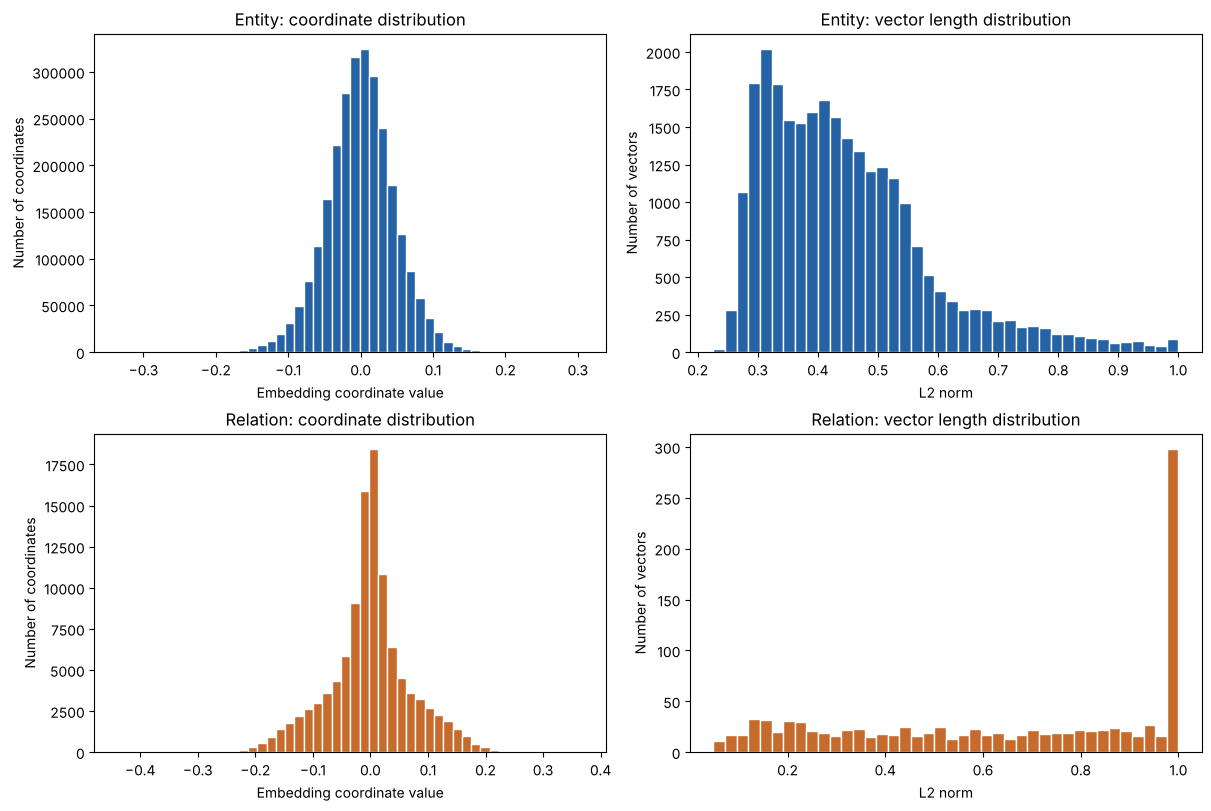

In [12]:
def vector_norm_table(df, id_column):
    values = df[embedding_columns].to_numpy()
    finite_rows = np.isfinite(values).all(axis=1)
    norms = np.full(len(df), np.nan)
    norms[finite_rows] = np.linalg.norm(values[finite_rows], axis=1)
    return pd.DataFrame({
        id_column: df[id_column].to_numpy(),
        "all_coordinates_finite": finite_rows,
        "l2_norm": norms,
    })

entity_norms = vector_norm_table(entity_embeddings, "entity_id")
relation_norms = vector_norm_table(relation_embeddings, "relation_id")
norm_summary = pd.DataFrame({
    "entity": entity_norms["l2_norm"].replace([np.inf, -np.inf], np.nan).describe(),
    "relation": relation_norms["l2_norm"].replace([np.inf, -np.inf], np.nan).describe(),
}).T.rename(columns={"count": "finite_norm_count", "50%": "median"})
display(norm_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for row, (label, df, norms, color) in enumerate([
    ("Entity", entity_embeddings, entity_norms, "#2563A6"),
    ("Relation", relation_embeddings, relation_norms, "#C66B2B"),
]):
    values = df[embedding_columns].to_numpy()
    axes[row, 0].hist(
        values[np.isfinite(values)], bins=50, color=color, edgecolor="white"
    )
    axes[row, 0].set(
        title=f"{label}: coordinate distribution",
        xlabel="Embedding coordinate value", ylabel="Number of coordinates"
    )
    axes[row, 1].hist(
        norms.loc[np.isfinite(norms["l2_norm"]), "l2_norm"],
        bins=40, color=color, edgecolor="white"
    )
    axes[row, 1].set(
        title=f"{label}: vector length distribution",
        xlabel="L2 norm", ylabel="Number of vectors"
    )
plt.show()


## 13. Optional: entity embedding coverage in news articles
Match the **WikidataId** inside `title_entities` / `abstract_entities` to the embedding **entity_id**. Do not match entity IDs to article `news_id`.

Two definitions are reported:
- **Present:** the ID occurs in the embedding file.
- **Usable for this check:** the ID has exactly one row, with all finite coordinates and a nonzero vector. This conservative definition is useful for later cosine-based features, but is not a universal model requirement.

IDs are combined and deduplicated within each article; they are not counts of textual occurrences. Invalid JSON stops with the affected article and column. Annotation entries missing IDs are counted separately.

Coverage for articles without linked entity IDs is undefined (NaN), not 0%. Every percentage below includes its numerator and denominator.


In [13]:
def read_linked_ids(value, article_id, field):
    if isinstance(value, list):
        annotations = value
    elif pd.isna(value) or not str(value).strip():
        return set(), 0
    else:
        try:
            annotations = json.loads(value)
        except (json.JSONDecodeError, TypeError) as exc:
            raise ValueError(
                f"Invalid entity JSON: article {article_id}, column {field}"
            ) from exc
    if not isinstance(annotations, list):
        raise ValueError(f"Expected an entity list: article {article_id}, {field}")
    ids, missing_ids = set(), 0
    for annotation in annotations:
        if not isinstance(annotation, dict):
            raise ValueError(f"Invalid entity entry: article {article_id}, {field}")
        entity_id = annotation.get("WikidataId")
        if isinstance(entity_id, str) and entity_id.strip():
            ids.add(entity_id.strip())
        else:
            missing_ids += 1
    return ids, missing_ids

required_news_columns = ["news_id", "title_entities", "abstract_entities"]
if not set(required_news_columns).issubset(news.columns):
    raise ValueError("Run the original news-loading cell first.")
if news["news_id"].isna().any() or news["news_id"].duplicated().any():
    raise ValueError("Review missing/duplicate news IDs before article coverage.")

present_entity_ids = set(entity_embeddings["entity_id"])
usable_entity_row = (
    ~entity_embeddings["entity_id"].duplicated(keep=False)
    & entity_norms["all_coordinates_finite"]
    & np.isfinite(entity_norms["l2_norm"])
    & entity_norms["l2_norm"].gt(0)
)
usable_entity_ids = set(entity_embeddings.loc[usable_entity_row, "entity_id"])
all_linked_ids, article_records = set(), []
annotations_without_ids = 0

for article_id, title_json, abstract_json in news[required_news_columns].itertuples(
    index=False, name=None
):
    title_ids, title_missing = read_linked_ids(
        title_json, article_id, "title_entities"
    )
    abstract_ids, abstract_missing = read_linked_ids(
        abstract_json, article_id, "abstract_entities"
    )
    linked_ids = title_ids | abstract_ids
    all_linked_ids.update(linked_ids)
    annotations_without_ids += title_missing + abstract_missing
    article_records.append({
        "news_id": article_id,
        "linked_entity_count": len(linked_ids),
        "present_entity_count": len(linked_ids & present_entity_ids),
        "usable_entity_count": len(linked_ids & usable_entity_ids),
    })

article_entity_coverage = pd.DataFrame(
    article_records,
    columns=["news_id", "linked_entity_count", "present_entity_count",
             "usable_entity_count"],
)
article_entity_coverage["usable_coverage_pct"] = (
    article_entity_coverage["usable_entity_count"]
    / article_entity_coverage["linked_entity_count"].replace(0, np.nan)
    * 100
)

def coverage_row(metric, numerator, denominator):
    return {
        "metric": metric, "numerator": numerator, "denominator": denominator,
        "percentage": 100 * numerator / denominator if denominator else np.nan,
    }

has_linked = article_entity_coverage["linked_entity_count"].gt(0)
has_usable = article_entity_coverage["usable_entity_count"].gt(0)
all_usable = has_linked & article_entity_coverage["usable_entity_count"].eq(
    article_entity_coverage["linked_entity_count"]
)
entity_coverage_summary = pd.DataFrame([
    coverage_row("Distinct linked IDs present in file",
                 len(all_linked_ids & present_entity_ids), len(all_linked_ids)),
    coverage_row("Distinct linked IDs with usable vector",
                 len(all_linked_ids & usable_entity_ids), len(all_linked_ids)),
    coverage_row("Articles with no linked IDs", int((~has_linked).sum()), len(news)),
    coverage_row("Articles with at least one usable vector",
                 int(has_usable.sum()), len(news)),
    coverage_row("All linked IDs usable, among articles with linked IDs",
                 int(all_usable.sum()), int(has_linked.sum())),
]).set_index("metric")
display(entity_coverage_summary.round(2))
print("Annotation entries without a valid WikidataId:", annotations_without_ids)
display(article_entity_coverage.head())

missing_entity_ids = sorted(all_linked_ids - present_entity_ids)
print("Distinct linked IDs absent from embedding file:", len(missing_entity_ids))
print("Examples:", missing_entity_ids[:10])


,numerator,denominator,percentage
metric,,,
Distinct linked IDs present in file,26904,27761,96.91
Distinct linked IDs with usable vector,26904,27761,96.91
Articles with no linked IDs,6795,51282,13.25
Articles with at least one usable vector,44265,51282,86.32
"All linked IDs usable, among articles with linked IDs",43012,44487,96.68


Annotation entries without a valid WikidataId: 0


,news_id,linked_entity_count,present_entity_count,usable_entity_count,usable_coverage_pct
0,N55528,3,3,3,100.0
1,N19639,1,1,1,100.0
2,N61837,1,1,1,100.0
3,N53526,1,1,1,100.0
4,N38324,3,3,3,100.0


Distinct linked IDs absent from embedding file: 857
Examples: ['Q1025508', 'Q1036595', 'Q1040098', 'Q1047011', 'Q1051521', 'Q1055125', 'Q1055190', 'Q1057792', 'Q10672709', 'Q1075514']


## 14. How to interpret these results in your report

| Output | What it supports |
|---|---|
| embedding_overview | Dataset size, dimensions, duplicates and data quality |
| coordinate_summary and dimension statistics | Numeric scale and descriptive statistics |
| norm_summary and the histograms | Zero vectors and unusual magnitudes |
| entity_coverage_summary | Availability of entity features and potential need for a fallback |
| article_entity_coverage | Per-article linked-ID counts and embedding coverage |

Important distinctions:
- Negative embedding values are normal learned coordinates, not negative user feedback.
- Individual coordinates are not named human concepts, and norm size is not popularity.
- Microsoft notes that some linked entities have no provided embedding.
- Relation vectors represent relationship types. The four supplied files do not provide the complete graph edge/triple list connecting entity pairs, so they do not directly support graph-degree EDA or article-level relation coverage.
- Coverage shows feature availability; experiments are still needed to determine whether the embeddings improve recommendations.
- These cells do not fit, normalise, impute or retrain embeddings.

Sources:

- [Official MIND file format and embeddings](https://github.com/msnews/msnews.github.io/blob/master/assets/doc/introduction.md)


## What comes next?
Once these cells run successfully, use `behaviors` and `news` for your group's EDA.

- Parse history strings into article ID lists and calculate history lengths.
- Parse candidate strings into article IDs and 0/1 labels while preserving impression IDs.
- Calculate slate lengths, exposures, clicks and click rates.
- Inspect text and entity information.
- Keep the development split separate. If you later inspect it, use separately named DataFrames or a separate notebook; avoid accidentally treating development records as training data.

The outputs are intentionally blank in this delivered notebook because your actual TSV files were not provided here. Run it in your Colab account to obtain your own results.

## References
- [Official MIND dataset website](https://msnews.github.io/)
- [Official MIND file format](https://github.com/msnews/msnews.github.io/blob/master/assets/doc/introduction.md)
